In [11]:
import hashlib
import os
import platform
import uuid
# 修改为自己的学号
STUDENT_ID = 20244081101
CONDA_ENV = os.environ.get("CONDA_DEFAULT_ENV")
print(f"[Conda 环境] {CONDA_ENV}")
MACHINE_FP = hashlib.sha256(
    f"{platform.node()}|{platform.machine()}|{platform.system()}|{uuid.getnode()}".encode()
).hexdigest()[:16]
RUN_ID = f"{STUDENT_ID}-{MACHINE_FP}"
print(f"[学号]\t{STUDENT_ID}")
print(f"[机器指纹] {MACHINE_FP}")
print(f"[RUN_ID] {RUN_ID}")

[Conda 环境] pyexp
[学号]	20244081101
[机器指纹] d24d45b16bc06106
[RUN_ID] 20244081101-d24d45b16bc06106


## 围绕半圆定律

半圆密度是

$$f(x)=\begin{cases}\dfrac{1}{2\pi}\sqrt{4-x^2}, & |x|\le 2,\\ 0, & |x|>2.\end{cases}$$

阶数为 $n$ 的 Wigner 矩阵：对 $1\le i\le j\le n$，从均值为 0、方差为 $1/n$ 的正态分布独立抽取 $Z_{ij}$，再令 $Z_{ji}=Z_{ij}$。

In [12]:
import numpy as np

def wigner_density(x):
    """半圆密度在 x 处的值。x 可以是 Python 或 NumPy 的整数、浮点数。"""
    value = float(x)
    if abs(value) > 2:
        return 0.0
    return float(np.sqrt(4 - value * value) / (2 * np.pi))

def generate_wigner(n):
    """生成 n 阶 Wigner 矩阵。n 不是正整数时抛出异常。"""
    if isinstance(n, bool) or not isinstance(n, (int, np.integer)):
        raise TypeError("n 必须是正整数")
    n = int(n)
    if n <= 0:
        raise ValueError("n 必须是正整数")
    scale = 1.0 / np.sqrt(n)
    noise = np.random.normal(loc=0.0, scale=scale, size=(n, n))
    matrix = np.triu(noise)
    matrix = matrix + np.triu(matrix, k=1).T
    return matrix

def get_spectrum(matrix):
    """返回全部特征值，按非递减顺序排列。"""
    values = np.linalg.eigvalsh(np.asarray(matrix, dtype=float))
    return np.sort(values)

print("wigner_density(0) =", wigner_density(0))
print("wigner_density(np.float64(1)) =", wigner_density(np.float64(1)))
print("wigner_density(2) =", wigner_density(2))
print("wigner_density(-3) =", wigner_density(-3))

np.random.seed(0)
sample = generate_wigner(4)
print("4 阶矩阵是否对称:", np.allclose(sample, sample.T))
print("特征值:", get_spectrum(sample))

for bad in [1.5, 0, -2, True, "4"]:
    try:
        generate_wigner(bad)
    except (TypeError, ValueError) as error:
        print(repr(bad), "->", type(error).__name__, error)

wigner_density(0) = 0.3183098861837907
wigner_density(np.float64(1)) = 0.27566444771089604
wigner_density(2) = 0.0
wigner_density(-3) = 0.0
4 阶矩阵是否对称: True
特征值: [-1.06018706 -0.42288844  0.03303699  2.0822847 ]
1.5 -> TypeError n 必须是正整数
0 -> ValueError n 必须是正整数
-2 -> ValueError n 必须是正整数
True -> TypeError n 必须是正整数
'4' -> TypeError n 必须是正整数


n =  100  KS 统计量 = 0.0196  p 值 = 1
n =  200  KS 统计量 = 0.0124  p 值 = 1
n =  500  KS 统计量 = 0.0057  p 值 = 1
n = 1000  KS 统计量 = 0.0040  p 值 = 1


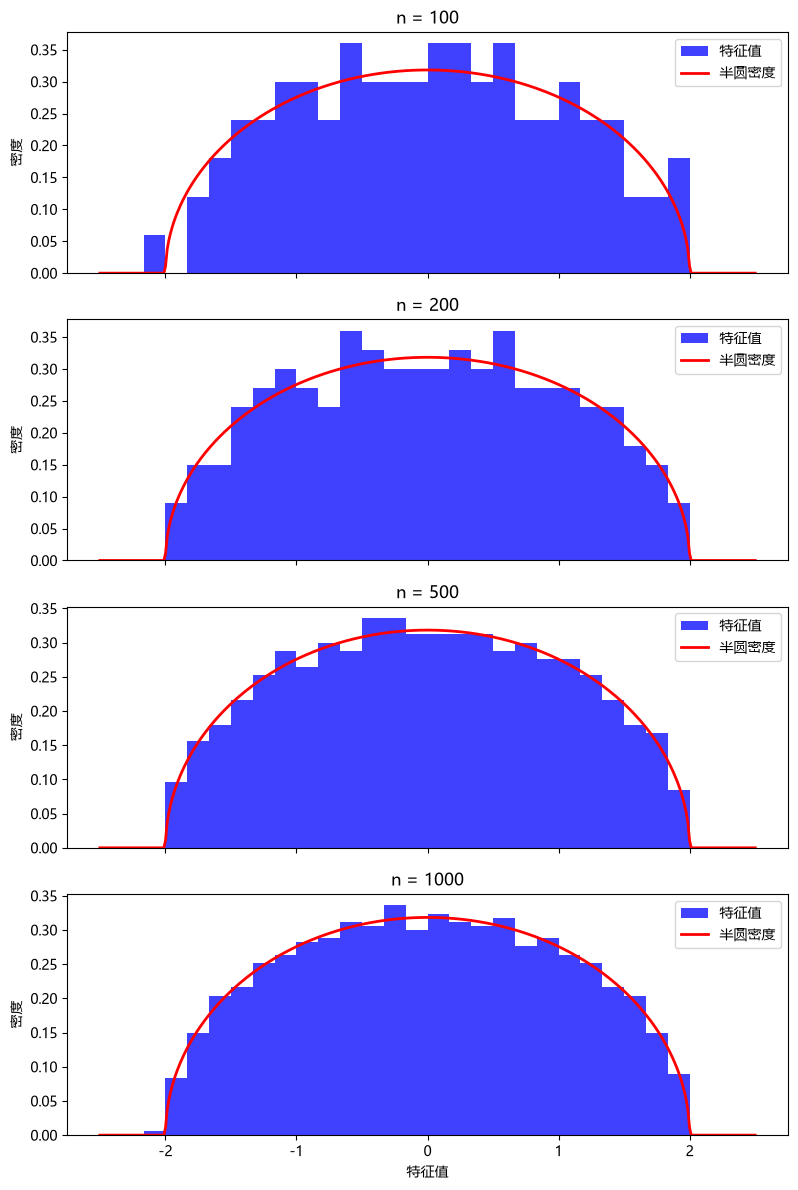

In [13]:
import matplotlib.pyplot as plt
from IPython.display import display
from scipy import stats

plt.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False

def semicircle_cdf(x):
    values = np.asarray(x, dtype=float)
    result = np.zeros(values.shape, dtype=float)
    result = np.where(values > 2, 1.0, result)
    inside = np.abs(values) <= 2
    clipped = np.clip(values, -2, 2)
    body = (
        0.5
        + clipped * np.sqrt(4 - clipped * clipped) / (4 * np.pi)
        + np.arcsin(clipped / 2) / np.pi
    )
    return np.where(inside, body, result)

orders = [100, 200, 500, 1000]
fig, axes = plt.subplots(len(orders), 1, figsize=(8, 12), sharex=True)
xs = np.linspace(-2.5, 2.5, 400)
density = np.array([wigner_density(x) for x in xs])
bins = np.linspace(-2.5, 2.5, 31)
np.random.seed(42)
for ax, n in zip(axes, orders):
    spectrum = get_spectrum(generate_wigner(n))
    ax.hist(
        spectrum,
        bins=bins,
        density=True,
        color="blue",
        alpha=0.75,
        label="特征值",
    )
    ax.plot(xs, density, color="red", linewidth=2, label="半圆密度")
    ax.set_ylabel("密度")
    ax.set_title(f"n = {n}")
    ax.legend(loc="upper right")
    ks = stats.kstest(spectrum, semicircle_cdf)
    print(f"n = {n:4d}  KS 统计量 = {ks.statistic:.4f}  p 值 = {ks.pvalue:.4g}")
axes[-1].set_xlabel("特征值")
fig.tight_layout()
display(fig)
plt.close(fig)

蓝色直方图已经按密度标准化，可以直接和红色半圆密度比较。`n = 100` 时柱子起伏很大，只大致有中间高、两边低的样子。`n = 200` 轮廓清楚一些，两端仍有偏差。`n = 500` 时主体已经贴着红线。`n = 1000` 时拟合更稳。

所以大约到 **500** 阶，半圆密度就能比较好地拟合特征值分布，1000 阶时更好。Kolmogorov–Smirnov 统计量从 n = 100 的 0.0196 降到 n = 1000 的 0.0040，和图形一致。这几组的 p 值都接近 1，按 0.05 的水平都不能拒绝“特征值来自半圆分布”。

## Conway 的生命游戏

棋盘是二维数组，1 表示活细胞，0 表示死细胞。邻居是周围八格，边界环绕：第一行的上邻居在最后一行，最后一列的右邻居在第一列。更新时用的是原来的棋盘，所有细胞同时变化。

一维数组: False
含有 2: False
普通列表: False
闪烁器:
[[0 0 0 0 0]
 [0 0 1 0 0]
 [0 0 1 0 0]
 [0 0 1 0 0]
 [0 0 0 0 0]]
下一步:
[[0 0 0 0 0]
 [0 0 0 0 0]
 [0 1 1 1 0]
 [0 0 0 0 0]
 [0 0 0 0 0]]


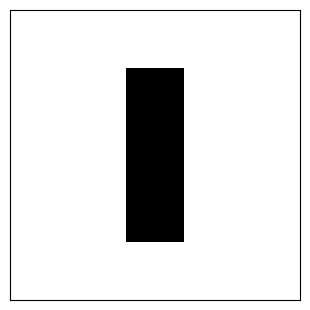

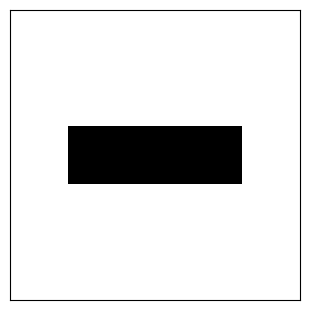

环绕边界的棋盘:
[[0 0 0 0 1]
 [0 0 0 0 0]
 [0 0 0 0 0]
 [0 0 0 0 0]
 [1 0 0 0 1]]
下一步，左上角靠三条边外的活邻居复活:
[[1 0 0 0 1]
 [0 0 0 0 0]
 [0 0 0 0 0]
 [0 0 0 0 0]
 [1 0 0 0 1]]
无效棋盘: board 必须是只含 0 和 1 的二维数组


In [14]:
def is_valid_board(board):
    if not isinstance(board, np.ndarray) or board.ndim != 2:
        return False
    return bool(np.isin(board, [0, 1]).all())

def gol_step(board):
    if not is_valid_board(board):
        raise ValueError("board 必须是只含 0 和 1 的二维数组")
    neighbors = (
        np.roll(np.roll(board, 1, axis=0), 1, axis=1)
        + np.roll(board, 1, axis=0)
        + np.roll(np.roll(board, 1, axis=0), -1, axis=1)
        + np.roll(board, 1, axis=1)
        + np.roll(board, -1, axis=1)
        + np.roll(np.roll(board, -1, axis=0), 1, axis=1)
        + np.roll(board, -1, axis=0)
        + np.roll(np.roll(board, -1, axis=0), -1, axis=1)
    )
    survive = (board == 1) & ((neighbors == 2) | (neighbors == 3))
    born = (board == 0) & (neighbors == 3)
    return (survive | born).astype(int)

def draw_gol_board(board):
    if not is_valid_board(board):
        raise ValueError("board 必须是只含 0 和 1 的二维数组")
    fig, ax = plt.subplots(figsize=(3.2, 3.2))
    ax.imshow(board, cmap=plt.get_cmap("gray_r"), vmin=0, vmax=1, interpolation="nearest")
    ax.set_xticks([])
    ax.set_yticks([])
    ax.grid(False)
    fig.tight_layout()
    return fig

print("一维数组:", is_valid_board(np.array([0, 1])))
print("含有 2:", is_valid_board(np.array([[0, 2], [1, 0]])))
print("普通列表:", is_valid_board([[0, 1], [1, 0]]))

blinker = np.zeros((5, 5), dtype=int)
blinker[1:4, 2] = 1
blinker_next = gol_step(blinker)
print("闪烁器:")
print(blinker)
print("下一步:")
print(blinker_next)
fig_now = draw_gol_board(blinker)
fig_next = draw_gol_board(blinker_next)
display(fig_now)
display(fig_next)
plt.close(fig_now)
plt.close(fig_next)

wrapped = np.zeros((5, 5), dtype=int)
wrapped[0, 4] = 1
wrapped[4, 0] = 1
wrapped[4, 4] = 1
print("环绕边界的棋盘:")
print(wrapped)
print("下一步，左上角靠三条边外的活邻居复活:")
print(gol_step(wrapped))

try:
    gol_step(np.array([[0, 2], [1, 0]]))
except ValueError as error:
    print("无效棋盘:", error)

棋盘取 5×5，把竖直三连放在中间，避免贴边时被环绕边界干扰。中间那个活细胞有两个活邻居，继续存活；左右两格各有三个活邻居，变成活细胞；上下两端只剩一个活邻居，死亡。下一步是横着的三连。图里黑格是活细胞，白格是死细胞，没有网格线、轴标签和刻度。

第二块棋盘的三个活细胞分别在右上角、左下角和右下角。左上角原来是死的，它的三个活邻居都在棋盘另一边，只有按环绕边界去数才会变成三个，所以下一步左上角复活，原来的三个活细胞各有两个活邻居，继续存活。

## 使用 pandas DataFrame


In [15]:
from pathlib import Path

import pandas as pd

candidates = [
    Path("iris.csv"),
    Path("作业三") / "iris.csv",
]
iris_path = next(path for path in candidates if path.exists())
iris = pd.read_csv(iris_path, index_col=0)
print("数据文件:", iris_path)
print("数据点数:", len(iris))
print("列名:", list(iris.columns))
print("各列数据类型:")
print(iris.dtypes)

sepal_length = "sepal length (cm)"
sepal_width = "sepal width (cm)"
petal_length = "petal length (cm)"
petal_width = "petal width (cm)"
iris["species"] = ["setosa"] * 50 + ["versicolor"] * 50 + ["virginica"] * 50
print("花卉种类数:", iris["species"].nunique())
print("种类:", iris["species"].unique().tolist())

print("修改前，索引 34 和 37:")
print(iris.loc[[34, 37]])
value_columns = [sepal_length, sepal_width, petal_length, petal_width, "species"]
iris.loc[34, value_columns] = [4.9, 3.1, 1.5, 0.2, "setosa"]
iris.loc[37, value_columns] = [4.9, 3.6, 1.4, 0.1, "setosa"]
print("修改后:")
print(iris.loc[[34, 37]])

iris["Petal.Ratio"] = iris[petal_length] / iris[petal_width]
iris["Sepal.Ratio"] = iris[sepal_length] / iris[sepal_width]
corrected_path = iris_path.with_name("iris_corrected.csv")
iris.to_csv(corrected_path, index=False)
print("已保存:", corrected_path)

ratio_summary = iris.groupby("species")[["Petal.Ratio", "Sepal.Ratio"]].agg(
    ["mean", "median", "min", "max", "std"]
)
print("按花卉种类汇总:")
print(ratio_summary)

数据文件: iris.csv
数据点数: 150
列名: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
各列数据类型:
sepal length (cm)    float64
sepal width (cm)     float64
petal length (cm)    float64
petal width (cm)     float64
dtype: object
花卉种类数: 3
种类: ['setosa', 'versicolor', 'virginica']
修改前，索引 34 和 37:
    sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
34                4.9               3.1                1.5               0.2   
37                4.9               3.6                NaN               0.1   

   species  
34  setosa  
37  setosa  
修改后:
    sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
34                4.9               3.1                1.5               0.2   
37                4.9               3.6                1.4               0.1   

   species  
34  setosa  
37  setosa  
已保存: iris_corrected.csv
按花卉种类汇总:
           Petal.Ratio                                     Sepal.Ratio  \
           

表里有 150 个数据点。四项测量是浮点数，列名是 `sepal length (cm)`、`sepal width (cm)`、`petal length (cm)`、`petal width (cm)`。原始文件没有种类列，按行顺序补上以后是 3 种：setosa、versicolor、virginica。

第 35 行（索引 34）的四项测量已经是 4.9、3.1、1.5、0.2，和作业给出的正确值一样。第 38 行（索引 37）原来是 4.9、3.6、空、0.1，花瓣长度是空的；按作业改成 4.9、3.6、1.4、0.1，种类写成 setosa。

`Petal.Ratio` 是花瓣长度除以花瓣宽度，`Sepal.Ratio` 是萼片长度除以萼片宽度。更正后的表写在 `iris_corrected.csv`。`groupby` 按种类给出这两个比值的平均值、中位数、最小值、最大值和标准差。